In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from scipy.stats import pearsonr
import mar

In [2]:
iyr=1980
fyr=2024
domain='GRf'; domainM='GRp'
var='T2M';units='°C'

In [3]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/'
plotsDir='/home/santolam/RECAP/figures/'


In [4]:
model1='MAR'
res1=str('7kmx7km')
nx=ny=10

ds_TTZ_raw= xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/{domainM}/spin2/work/monthly/'+
                           'TTZ_mon_MARv3.14_ER5_spin2_'+domainM+'_1980-2024.nc')['TTZ'][:,0,:,:] ## montlhy mean
ds_TTZ = ds_TTZ_raw.rename({'TIME': 'time'})
#units=ds_TTZ.units

ds1=ds_TTZ[:,ny:-ny,nx:-nx].sel(time=slice(str(iyr), str(fyr)))


In [5]:
ds_grid= xr.open_dataset('/home/santolam/NST.2014.01.01.00.GRi.nc')
LONS=ds_grid.LON[ny:-ny,nx:-nx].values
LATS=ds_grid.LAT[ny:-ny,nx:-nx].values
dsSH=ds_grid.SH[ny:-ny,nx:-nx]
dsICE=ds_grid.ICE[ny:-ny,nx:-nx]

In [6]:
field1_SH= dsSH.assign_coords({
    'lat': (('y', 'x'), LATS),
    'lon': (('y', 'x'),LONS)
})

In [7]:
field1=ds1.assign_coords({
    'lat': (('Y', 'X'), LATS),
    'lon': (('Y', 'X'),LONS)
})
#field1=field1.rename({"Y":"y","X":"x"})

In [8]:
print(field1_SH.shape,field1.shape)

(62, 96) (540, 62, 96)


In [9]:
###Select the real domain
latS=field1.lat.min(); latN=field1.lat.max()
lonW=field1.lon.min(); lonE=field1.lon.max()
print(latS.values,latN.values,lonW.values,lonE.values)

3.685060501098633e+01 40.75126647949219 68.39894104003906 76.28392028808594


In [10]:
model3='era5-land'
res3=str('0.1°x0.1°')

ds3_raw= xr.open_dataset(f'/bettik/PROJECTS/pr-regional-climate/santolam/era5-land/'+
                         't2m_mon.era5-land_1980-2024_HMA_01x01.nc')['t2m']
ds3=ds3_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
ds3=ds3.sel(time=slice(str(iyr),str(fyr)))-273.15

field3=ds3.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [11]:
ds3_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/'+
                       'gmted_on_t2m_era5-land_corrected.nc')['elevation']
ds3_SH=ds3_SH.rename({'latitude':'lat','longitude':'lon'})
field3_SH=ds3_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [12]:
print(field3_SH.shape,field3.shape)

(39, 79) (540, 39, 79)


In [13]:
print(field3.shape,field3_SH.shape)

(540, 39, 79) (39, 79)


In [14]:
model4='era5'
res4=str('0.25°x0.25°')
ds4_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/era5/'
                         +'t2m.mon_era5_1940-2025_HMA_025x025.nc')['t2m']
ds4=ds4_raw-273.15
ds4=ds4_raw.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
ds4=ds4.sel(time=slice(str(iyr),str(fyr)))-273.15

field4=ds4.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [15]:
ds4_SH=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_era5_grid.nc')['elevation']
ds4_SH=ds4_SH.rename({'latitude':'lat','longitude':'lon'})

field4_SH=ds4_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))


In [16]:
#print(field4.shape,field4_SH.shape)

In [17]:
#print(field4.lat[0:2],field3.lat[0:2])

In [18]:
model5='cru'
res5=str('0.5°x0.5°')

fileName5='cru_ts4.05.1901.2020.tmp.dat.nc'
ds5_raw= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+model5+'/'+fileName5)['tmp']
ds5=dom.reversing_lat(ds5_raw)
field5=ds5.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))
field5=field5.sel(time=slice(str(iyr),str(2020)))

In [19]:
#field5

In [20]:
ds5_SH_raw=xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/gmted/gmted_on_cru_hma_grid.nc')['elevation']
ds5_SH=dom.reversing_lat(ds5_SH_raw)
field5_SH=ds5_SH.sel(lat=slice(latN,latS),lon=slice(lonW,lonE))

In [21]:
#field5_SH[:,:].plot()

In [22]:
model7='HARv2'
res7='10kmx10km'
#variable='prcp'
fileName7='HARv2_mon_d10km_d_2d_t2_1980-2023.nc'
ds7_raw0= xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/santolam/'+'/'+model7+'/'+fileName7)['t2']
ds7=ds7_raw0 - 273.15

def xy_sel_dom(ds,latS,latN,lonW,lonE):
    #latS,latN,lonW,lonE,latlim,lonlim=dom.coord_domain(domain)
    lat_str = ''
    lon_str = ''
    other_dims_str = []
    for dim in ds.coords:
        print(dim)
        if dim in ['lat', 'latitude','LON']:
            lat_str = dim
        elif dim in ['lon', 'longitude','LAT']:
            lon_str = dim
        else:
            other_dims_str.append(dim)
    mask = (
        (latS < ds[lat_str]) & ( ds[lat_str] < latN) 
    & (lonW < ds[lon_str]) & ( ds[lon_str] < lonE)
    )
    field_dom=ds.where(mask,drop=True)
    return field_dom

# Apply mask (non-NaN where the condition is True)
#hgt_subset = hgt.where(mask, drop=True)
field7=xy_sel_dom(ds7.sel(time=slice(str(iyr),str(2023))),latS,latN,lonW,lonE)

time
lon
lat
west_east
south_north


In [23]:
#field7[0,:,:].plot()

In [24]:
fileName7_grF='HARv2_d10km_static_hgt.nc'
ds7_grM= xr.open_dataset(sourceData+'/'+model7+'/'+fileName7_grF)
ds7SH=ds7_grM['hgt'][0,:,:]
#dsSH
field7_SH=xy_sel_dom(ds7SH,latS,latN,lonW,lonE)


time
west_east
south_north
lon
lat


In [25]:

## SAME ANALYSIS BUT FOR multiple data sets(at the same time): lists

dsList=[field1,
        field3,field4,field5,
        field7]
modelList=[model1,
           model3,model4,model5,
           model7]
resList=[res1,
         res3,res4,res5,
         res7]
nameList=list(zip(modelList,resList))

In [26]:
nameList

[('MAR', '7kmx7km'),
 ('era5-land', '0.1°x0.1°'),
 ('era5', '0.25°x0.25°'),
 ('cru', '0.5°x0.5°'),
 ('HARv2', '10kmx10km')]

In [27]:
elevList=[field1_SH,field3_SH,field4_SH,field5_SH,field7_SH]
print(len(elevList))

5


In [28]:
#level_bounds = [(0, 2500), (2500, 4500), (4500, 5500), (5500, 7500)]
level_bounds = [(5500, 7500),(4500, 5500), (2500, 4500), (0, 2500) ]

In [29]:
maskList_field1 = []
for lev_min, lev_max in level_bounds:
    mask = (field1_SH >= lev_min) & (field1_SH < lev_max)
    maskList_field1.append(mask)

maskList_field3 = []
for lev_min, lev_max in level_bounds:
    mask = (field3_SH >= lev_min) & (field3_SH < lev_max)
    maskList_field3.append(mask)

maskList_field4 = []
for lev_min, lev_max in level_bounds:
    mask = (field4_SH >= lev_min) & (field4_SH < lev_max)
    maskList_field4.append(mask)

maskList_field5 = []
for lev_min, lev_max in level_bounds:
    mask = (field5_SH >= lev_min) & (field5_SH < lev_max)
    maskList_field5.append(mask)
    
maskList_field7 = []
for lev_min, lev_max in level_bounds:
    mask = (field7_SH >= lev_min) & (field7_SH < lev_max)
    maskList_field7.append(mask)

In [30]:
field1_season = field1.groupby('time.month').mean('time', skipna=True)
field3_season = field3.groupby('time.month').mean('time', skipna=True)
field4_season = field4.groupby('time.month').mean('time', skipna=True)
field5_season = field5.groupby('time.month').mean('time', skipna=True)
#field6_season = field6.groupby('time.month').mean('time', skipna=True)
field7_season = field7.groupby('time.month').mean('time', skipna=True)

def compute_mean_for_masks(field_season, mask_list, dims):
    mean_vals = []
    for mask in mask_list:
        masked = field_season.where(mask.values)
        for dim in dims:
            masked = masked.mean(dim)
        mean_vals.append(masked)
    return mean_vals

# Then apply it like this:
ac_mean_vals_field1 = compute_mean_for_masks(field1_season, maskList_field1,  ['X', 'Y'])
ac_mean_vals_field3 = compute_mean_for_masks(field3_season, maskList_field3, ['lon', 'lat'])
ac_mean_vals_field4= compute_mean_for_masks(field4_season, maskList_field4,  ['lon', 'lat'])
ac_mean_vals_field5= compute_mean_for_masks(field5_season, maskList_field5,  ['lon', 'lat'])
#ac_mean_vals_field6= compute_mean_for_masks(field6_season, maskList_field6,  ['lon', 'lat'])
ac_mean_vals_field7 = compute_mean_for_masks(field7_season, maskList_field7,  ['south_north', 'west_east'])

In [31]:
counts1 = [int(mask.sum()) for mask in maskList_field1]
counts3 = [int(mask.sum()) for mask in maskList_field3]
counts4 = [int(mask.sum()) for mask in maskList_field4]
counts5 = [int(mask.sum()) for mask in maskList_field5]
counts7 = [int(mask.sum()) for mask in maskList_field7]

In [32]:
counts1

[8, 797, 3104, 2043]

In [33]:
nameList#[0][1]

[('MAR', '7kmx7km'),
 ('era5-land', '0.1°x0.1°'),
 ('era5', '0.25°x0.25°'),
 ('cru', '0.5°x0.5°'),
 ('HARv2', '10kmx10km')]

In [34]:
nameListPlot=['MAR (7kmx7km)','ERA5-Land (0.1°x0.1°)', 'ERA5 (0.25°x0.25°)','CRU (0.5°x0.5°)', 'HARv2 (10kmx10km)']

In [35]:
diff_field3 = [ac_mean_vals_field1[i].values - ac_mean_vals_field3[i].values for i in range(4)]
diff_field4 = [ac_mean_vals_field1[i].values - ac_mean_vals_field4[i].values for i in range(4)]
diff_field5 = [ac_mean_vals_field1[i].values - ac_mean_vals_field5[i].values for i in range(4)]
diff_field7 = [ac_mean_vals_field1[i].values - ac_mean_vals_field7[i].values for i in range(4)]


/tmp/ipykernel_3128851/2509790727.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.1, 1, 0.95], h_pad=2)#plt.suptitle(f'Annual cycle {domainM} ({iyr}-{fyr})',fontsize=18,y=0.95,x=0.55)


Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG5_round4_annual_cycle_by_elev_tas_pamir.png


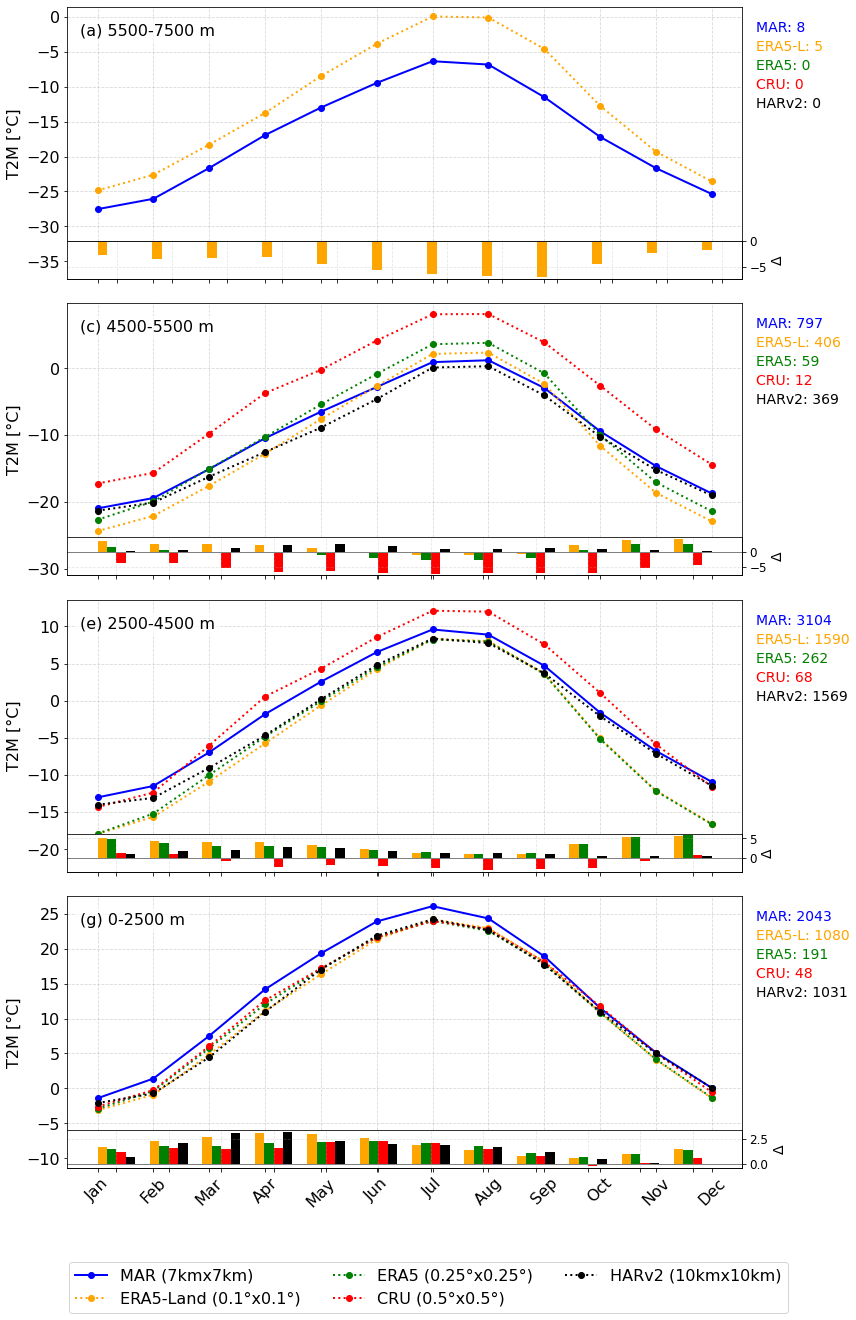

In [36]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

colorList=['b','orange', 'green', 'red', 'black']
markerList=['o','X','X','X','X','X']#

labels_fig=['(a)','(c)','(e)','(g)']
colors = colorList
elev_labels = ['5500-7500','4500-5500','2500-4500','0-2500']
months = np.arange(1, 13)

# --- Crear figura con 4 filas y 1 columna ---
fig, axs = plt.subplots(4, 1, figsize=(12, 20), sharex=True, sharey=False)
plt.subplots_adjust(hspace=0.5)
axs = axs.flatten()

for i, ax in enumerate(axs):
    ax.plot(months, ac_mean_vals_field1[i].values, 'o-', label=nameListPlot[0], color=colors[0], linewidth=2)
    ax.plot(months, ac_mean_vals_field3[i].values, 'o:', label=nameListPlot[1], color=colors[1], linewidth=2)
    ax.plot(months, ac_mean_vals_field4[i].values, 'o:', label=nameListPlot[2], color=colors[2], linewidth=2)
    ax.plot(months, ac_mean_vals_field5[i].values, 'o:', label=nameListPlot[3], color=colors[3], linewidth=2)
    ax.plot(months, ac_mean_vals_field7[i].values, 'o:', label=nameListPlot[4], color=colors[4], linewidth=2)
    ax.set_ylim(ac_mean_vals_field1[i].values.min()-10)
   
    bar_width = 0.18
    x_offset = [-0.27, -0.09, 0.09, 0.27]  # small offsets for 4 bars per month
       # Small inset for bias bars
    ax_inset = inset_axes(ax, width="100%", height="40%", loc='lower right',
                          #bbox_to_anchor=(0, 0., 1, 0.25),
                          bbox_to_anchor=(0, 0., 1, 0.35),  # move further down and taller
                          bbox_transform=ax.transAxes, borderpad=0)

    
    # Plot monthly biases
    ax_inset.bar(months + x_offset[0], diff_field3[i], width=bar_width, color=colors[1],  label='ERA5-L')
    ax_inset.bar(months + x_offset[1], diff_field4[i], width=bar_width, color=colors[2], label='ERA5')
    ax_inset.bar(months + x_offset[2], diff_field5[i], width=bar_width, color=colors[3], label='CRU')
    ax_inset.bar(months + x_offset[3], diff_field7[i], width=bar_width, color=colors[4],  label='HARv2')

    ax_inset.axhline(0, color='grey', lw=1)
    ax_inset.grid(True, linestyle='--', alpha=0.3)

# ---- Right-side y-axis ----
    ax_inset.yaxis.set_label_position("right")
    ax_inset.yaxis.tick_right()
    ax_inset.set_ylabel('Δ', fontsize=14, color='black')
    ax_inset.tick_params(axis='y', labelsize=12, colors='black')

# ---- X-axis setup ----
    ax_inset.set_xticks(months)
    ax_inset.set_xticklabels([])  # hide month names here (keeps top plot clean)
    #ax.set_title(f'Elevation {elev_labels[i]}', fontsize=14)
    ax.set_xticks(months)
    ax.set_ylabel(f'{var} [{units}]',fontsize=16)
    #ax.axhline(y=0, color='grey', linestyle='-', linewidth=1)
    ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                        'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45,fontsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.text(
    0.02, 0.94,                      # x, y in axes fraction (0–1)
    f'{labels_fig[i]} {elev_labels[i]} m',   # text string
    transform=ax.transAxes,          # interpret coords relative to axes
    fontsize=16,
    #fontweight='bold',
    va='top', ha='left',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')  # optional box
    )
    dy = 0.07  
    xpos = 1.02
    ypos = 0.95

    datasets = [
    ("MAR", counts1[i], colorList[0]),
    ("ERA5-L", counts3[i], colorList[1]),
    ("ERA5", counts4[i], colorList[2]),
    ("CRU", counts5[i], colorList[3]),
    ("HARv2", counts7[i], colorList[4]),
    ]

    for j, (name, count, color) in enumerate(datasets):
        ax.text(
        xpos, ypos - j * dy,
        f"{name}: {count}",
        color=color,
        transform=ax.transAxes,
        fontsize=14,
        va='top', ha='left',
        bbox=dict(facecolor='white', alpha=0.0, edgecolor='none')  # transparent background for each line
    )    #ax.set_aspect(0.5)

# Leyenda común abajo
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.03),
    ncol=3,
    fontsize=16,
    frameon=True
)

# Ajustar espacio para la leyenda
plt.tight_layout(rect=[0, 0.1, 1, 0.95], h_pad=2)#plt.suptitle(f'Annual cycle {domainM} ({iyr}-{fyr})',fontsize=18,y=0.95,x=0.55)

plotsDir="/home/santolam/RECAP/figures/paper_on_validation_RECAP/"

plotname=f'FIG5_round4_annual_cycle_by_elev_tas_pamir'
#fig.suptitle(plotname, fontsize=16)
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight")
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()
